# Recommendation Systems — Implementation Cheatsheet

Theory: [recommendation_systems.md](recommendation_systems.md) · Metrics: [evaluation_metrics.md](../01_toolkit/evaluation_metrics.md#5-recommendation-systems)

**Dataset:** MovieLens 100k: 100,000 ratings (1–5 stars) from 943 users on 1,682 movies. Downloaded automatically by `surprise` (~5 MB).
Same workflow as the Amazon Electronics project, which used the same library, metrics and threshold.

| # | Section |
|---|---|
| 1 | Setup & data |
| 2 | EDA: sparsity & long tail |
| 3 | Rank-based (popularity) |
| 4 | Surprise setup + evaluation function (Precision@k / Recall@k) |
| 5 | User-user collaborative filtering (KNN) |
| 6 | Item-item collaborative filtering (KNN) |
| 7 | Matrix factorization (SVD) |
| 8 | Clustering-based (CoClustering) |
| 9 | Model comparison |
| 10 | Making recommendations for a user |
| 11 | Content-based: "movies like this one" |

## 1. Setup & data

In [1]:
import os, warnings
from collections import defaultdict
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from surprise import Dataset, Reader, accuracy, KNNBasic, SVD, CoClustering
from surprise.model_selection import train_test_split, GridSearchCV
from surprise.builtin_datasets import BUILTIN_DATASETS, download_builtin_dataset, get_dataset_dir
from sklearn.metrics.pairwise import cosine_similarity

SEED = 1
# Download once without the interactive [Y/n] prompt
if not os.path.exists(BUILTIN_DATASETS["ml-100k"].path):
    download_builtin_dataset("ml-100k")
ml_dir = os.path.join(get_dataset_dir(), "ml-100k", "ml-100k")

ratings = pd.read_csv(os.path.join(ml_dir, "u.data"), sep="\t", names=["user_id", "item_id", "rating", "timestamp"])
genres = ["unknown", "Action", "Adventure", "Animation", "Children", "Comedy", "Crime", "Documentary", "Drama", "Fantasy",
          "Film-Noir", "Horror", "Musical", "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western"]
movies = pd.read_csv(os.path.join(ml_dir, "u.item"), sep="|", encoding="latin-1", header=None,
                     names=["item_id", "title", "release", "video", "url"] + genres)
movies = movies[["item_id", "title"] + genres]
ratings = ratings.drop(columns="timestamp")
print(ratings.shape, movies.shape)
ratings.merge(movies[["item_id", "title"]], on="item_id").head()

(100000, 3) (1682, 21)


,user_id,item_id,rating,title
0,196,242,3,Kolya (1996)
1,186,302,3,L.A. Confidential (1997)
2,22,377,1,Heavyweights (1994)
3,244,51,2,Legends of the Fall (1994)
4,166,346,1,Jackie Brown (1997)


## 2. EDA: sparsity & long tail

943 users × 1682 items = 1,586,126 possible ratings | observed 100,000 | sparsity 93.7%


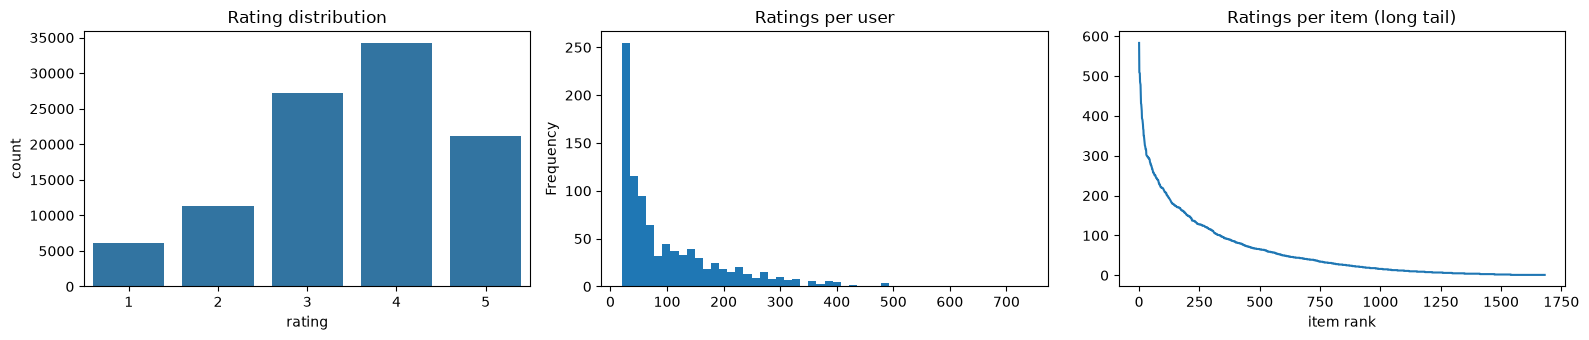

In [2]:
n_users, n_items = ratings["user_id"].nunique(), ratings["item_id"].nunique()
sparsity = 1 - len(ratings) / (n_users * n_items)
print(f"{n_users} users × {n_items} items = {n_users * n_items:,} possible ratings | observed {len(ratings):,} | sparsity {sparsity:.1%}")

fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
sns.countplot(data=ratings, x="rating", ax=ax[0]).set_title("Rating distribution")
ratings.groupby("user_id").size().plot(kind="hist", bins=50, ax=ax[1], title="Ratings per user")
ratings.groupby("item_id").size().sort_values(ascending=False).reset_index(drop=True).plot(ax=ax[2], title="Ratings per item (long tail)")
ax[2].set_xlabel("item rank")
plt.tight_layout(); plt.show()

**94% of the user-item matrix is empty**: that's what recommenders fill in. A few movies get most ratings (**long tail**), and every user has ≥ 20 ratings (MovieLens pre-filters, like the course's "users with ≥ 50 ratings" filter on Amazon).

## 3. Rank-based (popularity) recommender
Highest **average** rating among items with **enough ratings** (otherwise a movie with a single 5★ wins). Same for everyone, so it works for **new users** (cold start).

In [3]:
item_stats = ratings.groupby("item_id")["rating"].agg(avg_rating="mean", count_rating="count").reset_index()
item_stats = item_stats.merge(movies[["item_id", "title"]], on="item_id")

def top_n_products(stats, n, min_interactions):
    return (stats[stats["count_rating"] > min_interactions]
            .sort_values("avg_rating", ascending=False).head(n)[["title", "avg_rating", "count_rating"]])

print("Without a minimum (misleading):"); display(item_stats.sort_values("avg_rating", ascending=False).head(3)[["title", "avg_rating", "count_rating"]])
print("Top 5 with > 100 ratings:");      display(top_n_products(item_stats, 5, 100))

Without a minimum (misleading):


,title,avg_rating,count_rating
1188,Prefontaine (1997),5.0,3
1499,Santa with Muscles (1996),5.0,2
1200,Marlene Dietrich: Shadow and Light (1996),5.0,1


Top 5 with > 100 ratings:


,title,avg_rating,count_rating
407,"Close Shave, A (1995)",4.491071,112
317,Schindler's List (1993),4.466443,298
168,"Wrong Trousers, The (1993)",4.466102,118
482,Casablanca (1942),4.456790,243
63,"Shawshank Redemption, The (1994)",4.445230,283


## 4. Surprise setup + evaluation function
- `Reader(rating_scale=(1, 5))` + `Dataset.load_from_df(df[["user", "item", "rating"]])`
- **Relevant** item: true rating ≥ **3.5** · **Recommended** item: predicted rating ≥ 3.5, in the user's **top k = 10**

In [4]:
data = Dataset.load_from_df(ratings[["user_id", "item_id", "rating"]], Reader(rating_scale=(1, 5)))
trainset, testset = train_test_split(data, test_size=0.2, random_state=SEED)

results = {}

def precision_recall_at_k(model, name, k=10, threshold=3.5):
    """Fit on trainset, predict testset, report RMSE + Precision@k / Recall@k / F1@k (averaged over users)."""
    model.fit(trainset)
    predictions = model.test(testset)

    user_est_true = defaultdict(list)
    for uid, _, true_r, est, _ in predictions:
        user_est_true[uid].append((est, true_r))

    precisions, recalls = {}, {}
    for uid, user_ratings in user_est_true.items():
        user_ratings.sort(key=lambda x: x[0], reverse=True)             # rank by predicted rating
        n_rel = sum(true_r >= threshold for _, true_r in user_ratings)
        n_rec_k = sum(est >= threshold for est, _ in user_ratings[:k])
        n_rel_and_rec_k = sum((true_r >= threshold) and (est >= threshold) for est, true_r in user_ratings[:k])
        precisions[uid] = n_rel_and_rec_k / n_rec_k if n_rec_k else 0
        recalls[uid] = n_rel_and_rec_k / n_rel if n_rel else 0

    p, r = np.mean(list(precisions.values())), np.mean(list(recalls.values()))
    results[name] = {"RMSE": accuracy.rmse(predictions, verbose=False),
                     "Precision@10": p, "Recall@10": r, "F1@10": 2 * p * r / (p + r)}
    return pd.Series(results[name]).round(3)

## 5. User-user collaborative filtering
*Users who rated like you in the past will rate like you in the future.* The prediction is the similarity-weighted average of the **k most similar users'** ratings for that item.

In [5]:
sim_user = {"name": "cosine", "user_based": True}
precision_recall_at_k(KNNBasic(sim_options=sim_user, verbose=False, random_state=SEED), "User-user KNN (baseline)")

RMSE            1.021
Precision@10    0.700
Recall@10       0.571
F1@10           0.629
dtype: float64

In [6]:
param_grid = {"k": [20, 40, 60], "min_k": [3, 6], "sim_options": {"name": ["msd", "cosine", "pearson_baseline"], "user_based": [True]}}
gs = GridSearchCV(KNNBasic, param_grid, measures=["rmse"], cv=3, n_jobs=-1, joblib_verbose=0)
gs.fit(data)
print("best:", gs.best_params["rmse"], "| CV RMSE", round(gs.best_score["rmse"], 4))
user_knn = KNNBasic(**{k: v for k, v in gs.best_params["rmse"].items()}, verbose=False, random_state=SEED)
precision_recall_at_k(user_knn, "User-user KNN (tuned)")

best: {'k': 20, 'min_k': 3, 'sim_options': {'name': 'msd', 'user_based': True}} | CV RMSE 0.9868


RMSE            0.980
Precision@10    0.700
Recall@10       0.561
F1@10           0.623
dtype: float64

## 6. Item-item collaborative filtering
*Users who liked this item also liked…* Similar **items** instead of similar users. Usually more stable: items have more ratings than users and change less.

In [7]:
sim_item = {"name": "cosine", "user_based": False}
precision_recall_at_k(KNNBasic(sim_options=sim_item, verbose=False, random_state=SEED), "Item-item KNN (baseline)")

RMSE            1.031
Precision@10    0.553
Recall@10       0.493
F1@10           0.521
dtype: float64

In [8]:
param_grid = {"k": [20, 40, 60], "min_k": [3, 6], "sim_options": {"name": ["msd", "cosine", "pearson_baseline"], "user_based": [False]}}
gs = GridSearchCV(KNNBasic, param_grid, measures=["rmse"], cv=3, n_jobs=-1, joblib_verbose=0)
gs.fit(data)
print("best:", gs.best_params["rmse"], "| CV RMSE", round(gs.best_score["rmse"], 4))
item_knn = KNNBasic(**gs.best_params["rmse"], verbose=False, random_state=SEED)
precision_recall_at_k(item_knn, "Item-item KNN (tuned)")

best: {'k': 40, 'min_k': 3, 'sim_options': {'name': 'msd', 'user_based': False}} | CV RMSE 0.9848


RMSE            0.977
Precision@10    0.600
Recall@10       0.504
F1@10           0.548
dtype: float64

## 7. Matrix factorization (SVD)
Factorizes the rating matrix into **user** and **item latent factors** (hidden "tastes", e.g. *action vs drama*). Prediction = global mean + user bias + item bias + user·item factors. Learned with SGD and regularized.

In [9]:
precision_recall_at_k(SVD(random_state=SEED), "SVD (baseline)")

RMSE            0.941
Precision@10    0.695
Recall@10       0.540
F1@10           0.608
dtype: float64

In [10]:
param_grid = {"n_factors": [50, 100], "n_epochs": [20, 30], "lr_all": [0.005, 0.01], "reg_all": [0.02, 0.1]}
gs = GridSearchCV(SVD, param_grid, measures=["rmse"], cv=3, n_jobs=-1, joblib_verbose=0)
gs.fit(data)
print("best:", gs.best_params["rmse"], "| CV RMSE", round(gs.best_score["rmse"], 4))
svd = SVD(**gs.best_params["rmse"], random_state=SEED)
precision_recall_at_k(svd, "SVD (tuned)")

best: {'n_factors': 100, 'n_epochs': 30, 'lr_all': 0.01, 'reg_all': 0.1} | CV RMSE 0.9214


RMSE            0.915
Precision@10    0.707
Recall@10       0.551
F1@10           0.619
dtype: float64

## 8. Clustering-based (CoClustering)
Clusters users and items **at the same time**; prediction uses the averages of the user's cluster, the item's cluster and their co-cluster.

In [11]:
precision_recall_at_k(CoClustering(n_cltr_u=3, n_cltr_i=3, random_state=SEED), "CoClustering")

RMSE            0.975
Precision@10    0.665
Recall@10       0.509
F1@10           0.577
dtype: float64

## 9. Model comparison (test set)

In [12]:
comparison = pd.DataFrame(results).T.round(3).sort_values("RMSE")
comparison.style.background_gradient(cmap="Greens_r", subset=["RMSE"]).background_gradient(cmap="Greens", subset=["F1@10"])

,RMSE,Precision@10,Recall@10,F1@10
SVD (tuned),0.915000,0.707000,0.551000,0.619000
SVD (baseline),0.941000,0.695000,0.540000,0.608000
CoClustering,0.975000,0.665000,0.509000,0.577000
Item-item KNN (tuned),0.977000,0.600000,0.504000,0.548000
User-user KNN (tuned),0.980000,0.700000,0.561000,0.623000
User-user KNN (baseline),1.021000,0.700000,0.571000,0.629000
Item-item KNN (baseline),1.031000,0.553000,0.493000,0.521000


**How to read it**
- **RMSE**: how close predicted ratings are (lower = better). **Precision / Recall / F1 @10**: quality of the top-10 list (higher = better).
- **SVD (tuned)** wins on **RMSE (~0.92)** and **Precision@10 (~0.71)**, which is why matrix factorization is the classic production choice.
- Tuning (mainly switching the similarity to `msd`) improved the KNN models' RMSE (~1.02 → ~0.98).
- **RMSE and top-k metrics don't always agree**: the *baseline* user-user KNN has a slightly higher F1@10 than tuned SVD. Tune for the metric the business cares about (`GridSearchCV` here optimizes RMSE).
- Item-item KNN has a similar RMSE but the weakest **top-k** scores (Precision@10 ~0.60): MovieLens has many items with very few ratings, so item neighborhoods are noisy.

## 10. Making recommendations for a user

In [13]:
def recommend(model, user_id, n=5):
    """Predict a rating for every item the user has NOT rated and return the top n."""
    seen = set(ratings.loc[ratings["user_id"] == user_id, "item_id"])
    candidates = [i for i in ratings["item_id"].unique() if i not in seen]
    preds = [(i, model.predict(user_id, i).est) for i in candidates]
    top = pd.DataFrame(sorted(preds, key=lambda x: x[1], reverse=True)[:n], columns=["item_id", "predicted_rating"])
    return top.merge(movies[["item_id", "title"]], on="item_id")[["title", "predicted_rating"]].round(2)

USER = 42
best_model = SVD(**gs.best_params["rmse"], random_state=SEED).fit(data.build_full_trainset())   # refit on ALL data
print(f"User {USER} rated highest:")
display(ratings[ratings["user_id"] == USER].merge(movies[["item_id", "title"]], on="item_id")
        .sort_values("rating", ascending=False).head(5)[["title", "rating"]])
print(f"Recommended for user {USER} (SVD):")
recommend(best_model, USER)

User 42 rated highest:


,title,rating
0,E.T. the Extra-Terrestrial (1982),5
2,Terminator 2: Judgment Day (1991),5
6,Beauty and the Beast (1991),5
5,Sabrina (1995),5
14,"Terminator, The (1984)",5


Recommended for user 42 (SVD):


,title,predicted_rating
0,Titanic (1997),4.55
1,Braveheart (1995),4.49
2,Pather Panchali (1955),4.44
3,"Wrong Trousers, The (1993)",4.34
4,"Great Escape, The (1963)",4.31


In [14]:
# Predicting a single rating: est = predicted rating, details tells whether it was possible
print(best_model.predict(uid=USER, iid=50))         # 50 = Star Wars
print(best_model.predict(uid=99999, iid=50))         # unknown user (cold start)
print("global mean:", round(best_model.trainset.global_mean, 2))

user: 42         item: 50         r_ui = None   est = 4.55   {'was_impossible': False}
user: 99999      item: 50         r_ui = None   est = 4.27   {'was_impossible': False}
global mean: 3.53


**Cold start:** for an unknown user, SVD can't use user factors, so it predicts **global mean + item bias**. Star Wars still scores high because it's a well-liked movie, which is effectively a popularity recommendation. (KNN models instead return the global mean with `was_impossible=True`.)

## 11. Content-based: "movies like this one"
Uses item **attributes** (here: genres) instead of ratings, so it works for **brand-new items** with no ratings yet.

In [15]:
genre_matrix = movies.set_index("title")[genres]
sim = pd.DataFrame(cosine_similarity(genre_matrix), index=genre_matrix.index, columns=genre_matrix.index)

def similar_movies(title, n=5):
    return sim[title].drop(title).sort_values(ascending=False).head(n).round(2)

similar_movies("Toy Story (1995)")

title
Aladdin and the King of Thieves (1996)    1.00
Goofy Movie, A (1995)                     0.87
Aladdin (1992)                            0.87
Gumby: The Movie (1995)                   0.82
Home Alone (1990)                         0.82
Name: Toy Story (1995), dtype: float64

Genre-only similarity is crude (Toy Story → Aladdin's direct-to-video sequel, Gumby). Real systems use richer features (descriptions with **TF-IDF**, embeddings, cast) and combine content + collaborative signals in **hybrid** recommenders.